# When Does an Industrial Dryer Need Cleaning?

At a fertilizer plant, granules are dried in a large rotating drum heated by hot gas. Deposits slowly build up on the drum's walls, until it has to be stopped and cleaned. An unplanned stop costs production; cleaning too early wastes time.

The question: can the plant's sensors warn a few days ahead that a cleaning will soon be needed?

1. How deposits show up in the sensors.
2. Features that separate "deposits building up" from normal changes in production.
3. A warning model, tested on cleanings it never saw, against a simple rule of cleaning every N days.

**Data:** synthetic, generated by [make_data.py](make_data.py): 18 months of hourly sensor readings and the dates of 28 cleanings.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier, IsolationForest
from sklearn.linear_model import LinearRegression
from sklearn.metrics import roc_auc_score

plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.spines.top": False, "axes.spines.right": False})

In [2]:
sensors = pd.read_csv("sensors.csv.gz", parse_dates=["time"], index_col="time")
cleanings = pd.read_csv("cleanings.csv", parse_dates=["stopped", "restarted"])
print(f"{len(sensors):,} hours, {len(cleanings)} cleanings, every {cleanings.stopped.diff().mean().days} days on average")
sensors.describe().T.round(2)

13,128 hours, 28 cleanings, every 19 days on average


,count,mean,std,min,25%,50%,75%,max
production_t_h,12543.0,55.01,3.61,41.90,52.60,55.00,57.50,63.20
inlet_gas_temp_c,12543.0,559.96,6.19,534.20,555.70,560.00,564.20,584.20
exhaust_temp_c,12543.0,98.57,4.58,86.20,95.30,98.00,101.30,115.10
gas_flow_knm3_h,12543.0,114.48,9.85,81.40,107.90,114.80,121.30,148.40
pressure_drop_kpa,12543.0,2.36,0.38,1.56,2.07,2.25,2.56,3.75
drum_motor_kw,12543.0,421.45,14.93,375.00,410.80,419.50,430.30,477.40
product_moisture_pct,12543.0,1.23,0.18,0.64,1.10,1.21,1.34,2.01


## 1. How deposits show up

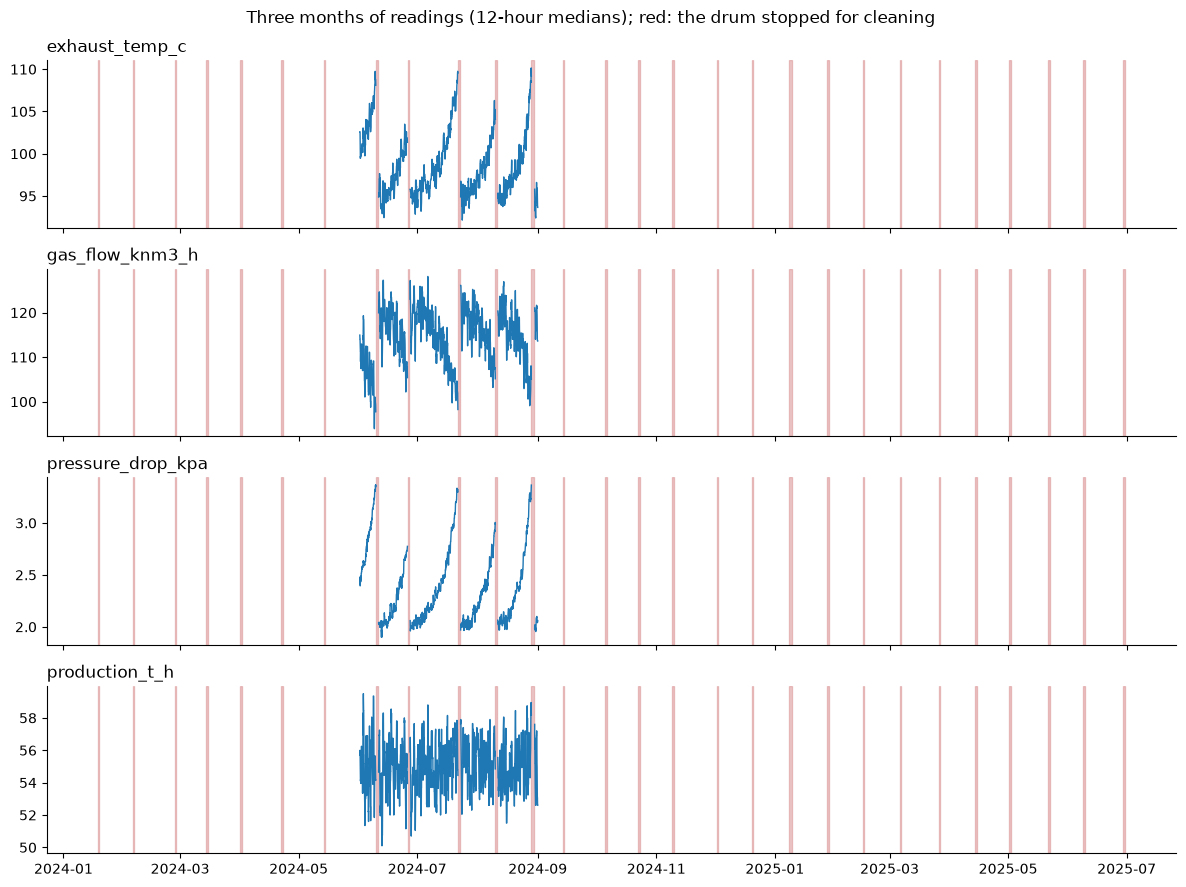

In [3]:
window = sensors.loc["2024-06-01":"2024-08-31"]
cols = ["exhaust_temp_c", "gas_flow_knm3_h", "pressure_drop_kpa", "production_t_h"]
fig, axes = plt.subplots(len(cols), 1, figsize=(12, 9), sharex=True)
for ax, col in zip(axes, cols):
    ax.plot(window[col].rolling(12).median(), lw=1)
    ax.set_title(col, loc="left")
    for _, c in cleanings.iterrows():
        ax.axvspan(c.stopped, c.restarted, color="#c44e52", alpha=0.3)
fig.suptitle("Three months of readings (12-hour medians); red: the drum stopped for cleaning")
plt.tight_layout()
plt.show()

Before each cleaning the exhaust gets hotter, the gas flow drops, and the pressure drop across the drum rises. But these readings also move with production: a higher load heats the exhaust and pushes more gas. To see the deposits, the effect of the load has to be taken out.

## 2. Features

**Load-corrected readings.** For each sensor, a straight-line model of how it depends on production is fitted on the first three days after every cleaning, when the drum is clean. The difference between the actual reading and what a clean drum would show at that load is the deposit signal.

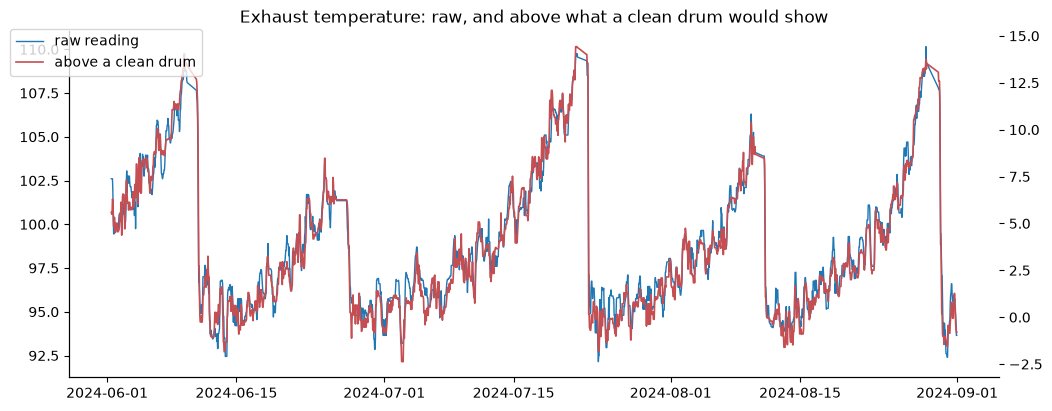

In [4]:
running = sensors.dropna()
after_clean = pd.Series(False, index=running.index)
for _, c in cleanings.iterrows():
    after_clean |= (running.index >= c.restarted) & (running.index < c.restarted + pd.Timedelta(days=3))

signals = ["exhaust_temp_c", "gas_flow_knm3_h", "pressure_drop_kpa", "drum_motor_kw", "product_moisture_pct"]
excess = pd.DataFrame(index=running.index)
for col in signals:
    clean = LinearRegression().fit(running.loc[after_clean, ["production_t_h", "inlet_gas_temp_c"]], running.loc[after_clean, col])
    excess[col] = running[col] - clean.predict(running[["production_t_h", "inlet_gas_temp_c"]])

fig, ax = plt.subplots()
ax.plot(running.loc["2024-06-01":"2024-08-31", "exhaust_temp_c"].rolling(12).median(), lw=1, label="raw reading")
ax2 = ax.twinx()
ax2.plot(excess.loc["2024-06-01":"2024-08-31", "exhaust_temp_c"].rolling(12).median(), color="#c44e52", lw=1.2, label="above a clean drum")
ax.set_title("Exhaust temperature: raw, and above what a clean drum would show")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.9))
plt.show()

The signal climbs steadily between cleanings and drops back after each one. In this data production varies only a little, so the raw and corrected lines nearly coincide; the correction matters more at a plant whose load changes a lot.

**Smoothing and trends.** Single hourly readings are noisy, so each signal becomes a 12-hour median, plus its change over the last 6 hours and 24 hours. The hours since the last cleaning are added too.

**What to predict.** An hour is labeled 1 if a cleaning starts within the next 72 hours.

In [5]:
features = pd.DataFrame(index=excess.index)
for col in signals:
    smooth = excess[col].rolling(12, min_periods=6).median()
    features[col] = smooth
    features[col + "_change_6h"] = smooth - smooth.shift(6)
    features[col + "_change_24h"] = smooth - smooth.shift(24)

last_restart = pd.Series(cleanings.restarted.values, index=cleanings.restarted).reindex(features.index, method="ffill")
features["hours_since_cleaning"] = (features.index.to_series() - last_restart.fillna(features.index[0])).dt.total_seconds() / 3600
next_stop = pd.Series(cleanings.stopped.values, index=cleanings.stopped).reindex(features.index, method="bfill")
hours_to_stop = (next_stop - features.index.to_series()).dt.total_seconds() / 3600
features["label"] = (hours_to_stop <= 72).astype(int)
features["hours_to_stop"] = hours_to_stop
features = features.dropna(subset=[c for c in features.columns if c != "hours_to_stop"])
print(f"{len(features):,} hours, {features.label.mean():.1%} of them within 72 hours of a cleaning")

12,514 hours, 16.1% of them within 72 hours of a cleaning


## 3. A warning model

The split is by time: the model trains on the first 12 months and is tested on the last 6, as it would be used. A warning is raised when the predicted chance stays above 50% for 3 hours in a row.

In [6]:
split = pd.Timestamp("2025-01-01")
X_cols = [c for c in features.columns if c not in ("label", "hours_to_stop")]
train, test = features[features.index < split], features[features.index >= split]

model = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=0)
model.fit(train[X_cols], train.label)
chance = pd.Series(model.predict_proba(test[X_cols])[:, 1], index=test.index)
print(f"ROC AUC on the last 6 months: {roc_auc_score(test.label, chance):.3f}")

ROC AUC on the last 6 months: 0.979


In [7]:
def evaluate(alarm, name):
    rows = []
    for _, c in cleanings[cleanings.stopped >= split].iterrows():
        before = alarm[(alarm.index >= c.stopped - pd.Timedelta(days=7)) & (alarm.index < c.stopped)]
        first = before[before].index.min()
        rows.append((c.stopped, (c.stopped - first).total_seconds() / 3600 if pd.notna(first) else np.nan))
    lead = pd.DataFrame(rows, columns=["cleaning", "warning hours ahead"])
    # a false alarm: a warning episode starting more than 7 days before the next cleaning
    starts = alarm & ~alarm.shift(1, fill_value=False)
    false = (starts & (test.hours_to_stop > 7 * 24)).sum()
    return {"cleanings warned": lead["warning hours ahead"].notna().mean(), "median hours of warning": lead["warning hours ahead"].median(),
            "false alarms": int(false)}, lead

alarm_model = (chance > 0.5).rolling(3).sum().eq(3)
summary_model, lead_model = evaluate(alarm_model, "model")
lead_model

,cleaning,warning hours ahead
0,2025-01-08 12:00:00,104.0
1,2025-01-28 01:00:00,87.0
2,2025-02-15 10:00:00,77.0
3,2025-03-06 05:00:00,98.0
4,2025-03-26 11:00:00,116.0
5,2025-04-14 04:00:00,108.0
6,2025-05-01 08:00:00,39.0
7,2025-05-21 13:00:00,103.0
8,2025-06-08 16:00:00,NaN
9,2025-06-29 02:00:00,126.0


**The simple rule to beat:** warn once the drum has run as long as the typical interval minus 3 days, with the interval taken from the training period.

In [8]:
typical = (train.hours_since_cleaning + train.hours_to_stop)[train.label == 1].median()
alarm_rule = test.hours_since_cleaning > typical - 72
summary_rule, lead_rule = evaluate(alarm_rule, "rule")
print(f"typical run between cleanings in training: {typical / 24:.1f} days")
pd.DataFrame({"warn after a fixed time": summary_rule, "sensor model": summary_model}).T

typical run between cleanings in training: 17.8 days


,cleanings warned,median hours of warning,false alarms
warn after a fixed time,1.0,83.5,0.0
sensor model,0.9,103.0,0.0


**Without labels.** The original analysis also tried an Isolation Forest, which flags hours that look unusual without knowing when cleanings happened. Its anomaly score against the time left before a cleaning:

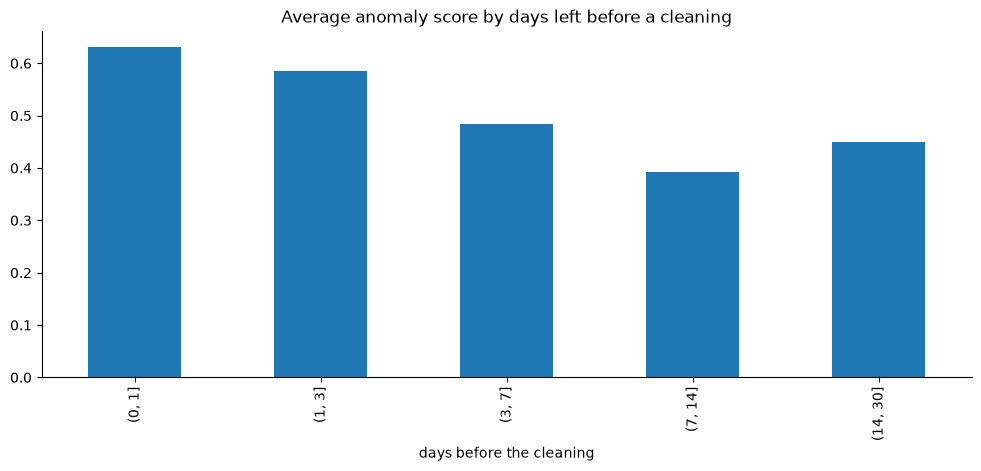

ROC AUC of the anomaly score for the 72-hour label: 0.942


In [9]:
iso = IsolationForest(n_estimators=200, random_state=42).fit(train.loc[train.hours_to_stop > 7 * 24, X_cols])
score = pd.Series(-iso.score_samples(test[X_cols]), index=test.index)
bins = pd.cut(test.hours_to_stop / 24, [0, 1, 3, 7, 14, 30])
ax = score.groupby(bins, observed=True).mean().plot.bar(title="Average anomaly score by days left before a cleaning")
ax.set_xlabel("days before the cleaning")
plt.show()
print(f"ROC AUC of the anomaly score for the 72-hour label: {roc_auc_score(test.label, score):.3f}")

In [10]:
from sklearn.inspection import permutation_importance
perm = permutation_importance(model, test[X_cols], test.label, n_repeats=5, random_state=0, scoring="roc_auc")
pd.Series(perm.importances_mean, index=X_cols).sort_values(ascending=False).head(8).round(3).rename("drop in AUC when shuffled")

hours_since_cleaning            0.039
pressure_drop_kpa               0.019
drum_motor_kw                   0.014
gas_flow_knm3_h                 0.005
exhaust_temp_c                  0.001
pressure_drop_kpa_change_24h    0.001
exhaust_temp_c_change_24h       0.001
product_moisture_pct            0.001
Name: drop in AUC when shuffled, dtype: float64

## Results

- Deposits show up as a slow climb in exhaust temperature, drum motor power, and pressure drop, and a fall in gas flow, reset by each cleaning. Cleanings came every 19 days on average.
- On the last 6 months, which the model never saw, it separates the 72 hours before a cleaning from other hours very well (ROC AUC 0.98). It warned before 9 of 10 cleanings, a median of 103 hours (about 4 days) ahead, with no false alarms; one cleaning came without a warning.
- The simple rule, warning once the drum has run 3 days less than the typical interval (17.8 days), warned before all 10, a median of 84 hours ahead, also with no false alarms. With cleanings this regular, time since the last cleaning is the strongest single signal, and the model relies on it most, followed by the pressure drop and the drum motor power.
- The Isolation Forest, which never sees when cleanings happened, also picks up the build-up (ROC AUC 0.94): its anomaly score rises as a cleaning approaches.
- The sensor model's advantage is about a day of extra warning. It would matter more where deposits build up at an uneven pace, when a fixed schedule either stops the drum too early or misses a fast build-up.

## Tools

Python, pandas, NumPy, scikit-learn (gradient boosting, Isolation Forest, linear regression), matplotlib